# 01 · Exploración de BTCUSDT

**Objetivo:** conocer los datos antes de modelar. Calidad, comportamiento de los
retornos, volatilidad, caídas desde máximos y volumen, con foco en lo que importa
para la metodología Wyckoff (rangos de compresión y relación esfuerzo/resultado).

**Datos:** velas de Binance descargadas con `btc-descargar`
(`data/raw/BTCUSDT_1d.parquet` y `BTCUSDT_4h.parquet`), historial completo desde
el 17-08-2017. Solo velas cerradas, en UTC.

**Contenido**
1. Carga
2. Calidad de datos
3. Retornos
4. Volatilidad
5. Drawdown (caída desde máximos)
6. Volumen y presión compradora
7. Gráfico de velas
8. Conclusiones

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.io as pio
import seaborn as sns
from scipy import stats

from btc_radar.datos import cargar_velas, detectar_huecos
from btc_radar.graficos import grafico_velas
from btc_radar.indicadores import (
    drawdown,
    ratio_compra_agresiva,
    retornos_log,
    volatilidad_anualizada,
)

# Interactivo en JupyterLab + imagen PNG para que GitHub muestre los gráficos
pio.renderers.default = "plotly_mimetype+png"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

## 1. Carga

In [2]:
d = cargar_velas("1d")
h = cargar_velas("4h")
print(f"1d: {len(d):,} velas  {d.index.min():%Y-%m-%d} → {d.index.max():%Y-%m-%d}")
print(f"4h: {len(h):,} velas  {h.index.min():%Y-%m-%d} → {h.index.max():%Y-%m-%d}")
d.info()

1d: 3,384 velas  2017-08-17 → 2026-11-21
4h: 20,292 velas  2017-08-17 → 2026-11-22
<class 'pandas.DataFrame'>
DatetimeIndex: 3384 entries, 2017-08-17 00:00:00+00:00 to 2026-11-21 00:00:00+00:00
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype              
---  ------                  --------------  -----              
 0   open                    3384 non-null   float64            
 1   high                    3384 non-null   float64            
 2   low                     3384 non-null   float64            
 3   close                   3384 non-null   float64            
 4   volume                  3384 non-null   float64            
 5   close_time              3384 non-null   datetime64[us, UTC]
 6   quote_volume            3384 non-null   float64            
 7   trades                  3384 non-null   int64              
 8   taker_buy_volume        3384 non-null   float64            
 9   taker_buy_quote_volume  3384 non-null   float64      

In [3]:
d.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
open,3384.0,3.955308e+04,3.261281e+04,3188.01,9.524770e+03,2.943022e+04,6.381826e+04,1.246585e+05
high,3384.0,4.035642e+04,3.311388e+04,3276.50,9.732430e+03,3.004175e+04,6.476316e+04,1.261996e+05
low,3384.0,3.868049e+04,3.207121e+04,2817.00,9.251500e+03,2.898526e+04,6.253932e+04,1.230840e+05
close,3384.0,3.956965e+04,3.260908e+04,3189.02,9.528850e+03,2.943060e+04,6.381826e+04,1.246585e+05
volume,3384.0,5.823888e+04,7.430806e+04,228.11,2.132346e+04,3.627270e+04,6.157143e+04,7.607054e+05
quote_volume,3384.0,1.723202e+09,1.857023e+09,977865.73,4.235918e+08,1.195008e+09,2.305186e+09,1.746531e+10
trades,3384.0,2.036926e+06,2.231617e+06,2153.00,4.728808e+05,1.260194e+06,2.733506e+06,1.536401e+07
taker_buy_volume,3384.0,2.891835e+04,3.698880e+04,56.19,1.057191e+04,1.813989e+04,3.048393e+04,3.747756e+05
taker_buy_quote_volume,3384.0,8.508202e+08,9.221628e+08,241363.80,2.097063e+08,5.844271e+08,1.133711e+09,8.783916e+09


## 2. Calidad de datos

Se revisan nulos, duplicados y **huecos temporales** (velas que deberían existir
y no están).

In [4]:
for nombre, df in [("1d", d), ("4h", h)]:
    print(
        f"{nombre}: nulos={df.isna().sum().sum()}, "
        f"duplicados={df.index.duplicated().sum()}, "
        f"huecos={len(detectar_huecos(df, nombre))}"
    )

huecos_4h = detectar_huecos(h, "4h")
print(
    f"\nVelas 4h faltantes: {huecos_4h['velas_faltantes'].sum()} "
    f"({huecos_4h['velas_faltantes'].sum() / len(h):.2%} del total)"
)
huecos_4h

1d: nulos=0, duplicados=0, huecos=0
4h: nulos=0, duplicados=0, huecos=8

Velas 4h faltantes: 16 (0.08% del total)


,desde,hasta,velas_faltantes
0,2018-02-08 04:00:00+00:00,2018-02-09 08:00:00+00:00,7
1,2018-06-26 04:00:00+00:00,2018-06-26 12:00:00+00:00,2
2,2018-07-04 04:00:00+00:00,2018-07-04 08:00:00+00:00,1
3,2018-11-14 04:00:00+00:00,2018-11-14 08:00:00+00:00,1
4,2019-03-12 04:00:00+00:00,2019-03-12 08:00:00+00:00,1
5,2019-05-15 04:00:00+00:00,2019-05-15 12:00:00+00:00,2
6,2019-08-15 04:00:00+00:00,2019-08-15 08:00:00+00:00,1
7,2020-02-19 12:00:00+00:00,2020-02-19 16:00:00+00:00,1


**Lectura:** no hay nulos ni duplicados. En 4h faltan 16 velas repartidas en
8 tramos, todos entre 2018 y 2020 (el mayor, ~1 día en febrero de 2018). Es
coherente con paradas del exchange en sus primeros años. La serie diaria no
tiene huecos.

**Decisión:** no se imputan precios inventados. Representan menos del 0,1 % de
la serie 4h y los indicadores trabajan sobre velas reales; se documentan aquí
para tenerlos en cuenta si una señal cae en esas fechas.

## 3. Retornos

Se usan **retornos logarítmicos** `ln(Pt / Pt-1)`: son aditivos en el tiempo y
simétricos (+10 % y −10 % log se compensan), lo que facilita la estadística.

In [5]:
r = retornos_log(d["close"]).dropna()
n_3sigma = (r.abs() > 3 * r.std()).sum()
esperado_normal = len(r) * 2 * stats.norm.sf(3)

pd.Series(
    {
        "media diaria": f"{r.mean():.4%}",
        "desv. estándar diaria": f"{r.std():.2%}",
        "asimetría (skew)": round(r.skew(), 2),
        "curtosis (exceso)": round(r.kurt(), 2),
        "días con |r| > 3σ": n_3sigma,
        "esperados si fuera normal": round(esperado_normal),
    }
)

media diaria                 0.0781%
desv. estándar diaria          3.52%
asimetría (skew)               -0.95
curtosis (exceso)              16.01
días con |r| > 3σ                 56
esperados si fuera normal          9
dtype: object

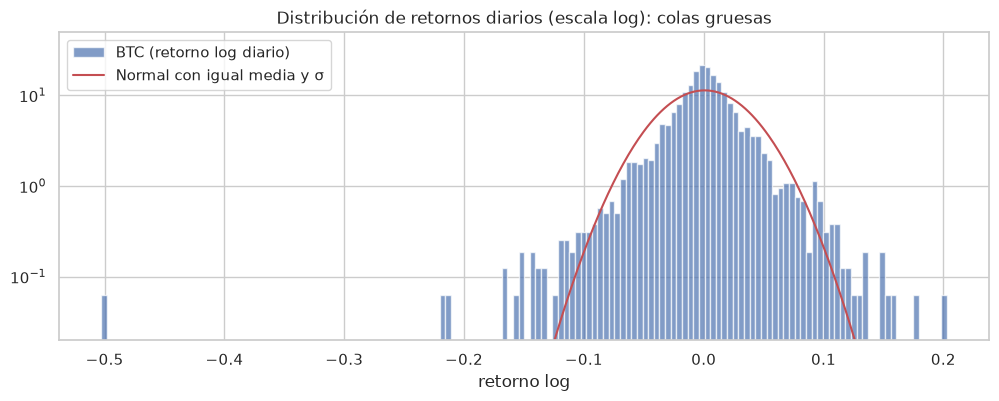

In [6]:
fig, ax = plt.subplots()
ax.hist(r, bins=150, density=True, alpha=0.7, label="BTC (retorno log diario)")
x = np.linspace(r.min(), r.max(), 500)
normal = stats.norm.pdf(x, r.mean(), r.std())
ax.plot(x, normal, "r", label="Normal con igual media y σ")
ax.set_yscale("log")
ax.set_ylim(0.02, 50)  # por debajo de 0,02 la normal ya es prácticamente 0
ax.set_title("Distribución de retornos diarios (escala log): colas gruesas")
ax.set_xlabel("retorno log")
ax.legend()
plt.show()

In [7]:
variacion = d["close"].pct_change()
pd.concat(
    {
        "peores días": variacion.nsmallest(5).mul(100).round(2).reset_index(),
        "mejores días": variacion.nlargest(5).mul(100).round(2).reset_index(),
    },
    axis=1,
)

peores días                     mejores días       
                  open_time  close                 open_time  close
0 2020-03-12 00:00:00+00:00 -39.50 2017-12-07 00:00:00+00:00  22.50
1 2018-01-16 00:00:00+00:00 -19.50 2021-02-08 00:00:00+00:00  19.54
2 2017-09-14 00:00:00+00:00 -19.16 2019-04-02 00:00:00+00:00  17.20
3 2022-06-13 00:00:00+00:00 -15.38 2019-10-25 00:00:00+00:00  16.76
4 2018-02-05 00:00:00+00:00 -15.21 2020-03-13 00:00:00+00:00  16.22

**Lectura:** los retornos **no son normales**. La curtosis es muy alta y hay
unas 6 veces más días extremos (> 3σ) de los que predice una distribución
normal. La asimetría negativa indica que las caídas extremas son más violentas
que las subidas. El peor día es el 12-03-2020 (−39,5 %, crash del COVID).

**Implicación:** cualquier stop o gestión de riesgo basada en "σ normal"
subestima el riesgo real. En el backtest (Fase 6) se medirán pérdidas reales,
no supuestos normales.

📝 *Tarea:* investiga qué ocurrió en el resto de fechas de la tabla y anótalo.

## 4. Volatilidad

Desviación estándar móvil de 30 días de los retornos log, anualizada con
√365 (cripto cotiza todos los días).

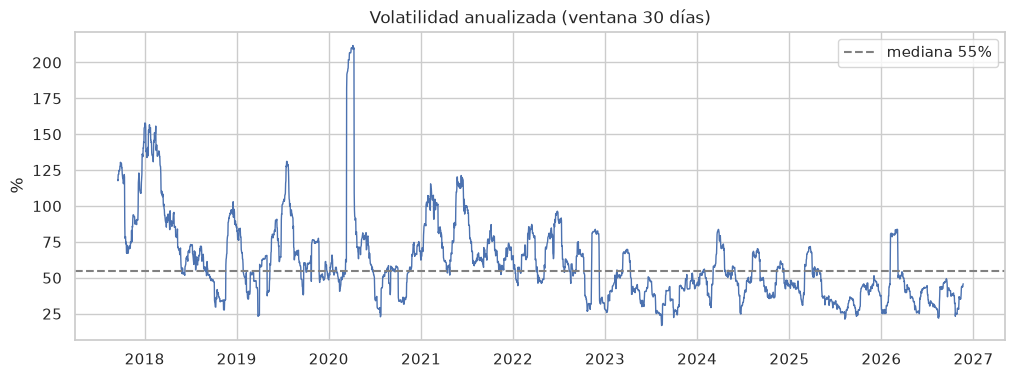

Actual: 45.9% | mínimo: 16.8% (2023-08-13) | máximo: 211.8% (2020-04-06)


open_time,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
vol. media anual %,102.4,80.9,66.3,68.0,78.8,63.1,41.6,51.0,40.9,41.3


In [8]:
vol = volatilidad_anualizada(d["close"], ventana=30)

fig, ax = plt.subplots()
ax.plot(vol.index, vol * 100, lw=1)
ax.axhline(
    vol.median() * 100, color="gray", ls="--", label=f"mediana {vol.median():.0%}"
)
ax.set_title("Volatilidad anualizada (ventana 30 días)")
ax.set_ylabel("%")
ax.legend()
plt.show()

print(
    f"Actual: {vol.iloc[-1]:.1%} | mínimo: {vol.min():.1%} ({vol.idxmin():%Y-%m-%d}) "
    f"| máximo: {vol.max():.1%} ({vol.idxmax():%Y-%m-%d})"
)
vol_anual = vol.groupby(vol.index.year).mean().mul(100).round(1)
vol_anual.rename("vol. media anual %").to_frame().T

**Lectura:** la volatilidad media anual cae de ~100 % en 2017 a ~40 % en
2025-2026: BTC es un activo cada vez más "maduro". El pico (~210 %) llega en
abril de 2020, tras el crash del COVID.

**Conexión con Wyckoff:** los periodos de **volatilidad baja** suelen coincidir
con **rangos laterales** (compresión), que es donde Wyckoff busca acumulación o
distribución. La volatilidad será una de las variables para detectar rangos en
la Fase 5.

## 5. Drawdown (caída desde máximos)

Cuánto está el precio por debajo del máximo de cierre previo.

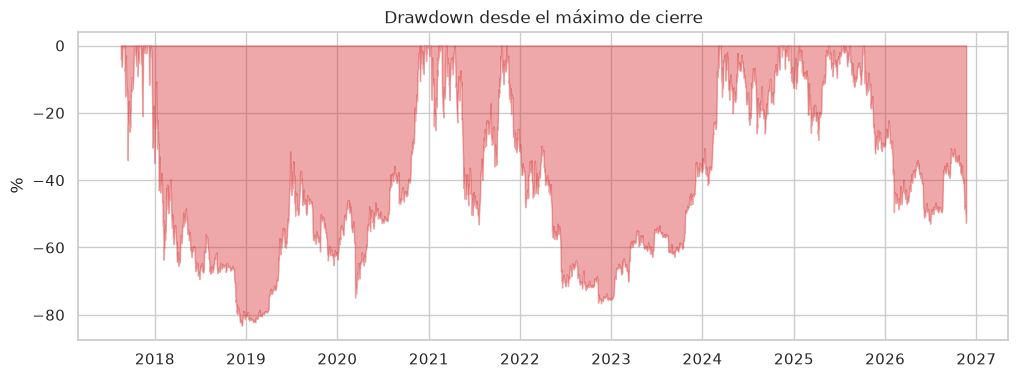

Máximo de cierre: 124,659 USDT (2025-10-06)
Peor drawdown: -83.2% (2018-12-15)
Drawdown actual: -51.7%


In [9]:
dd = drawdown(d["close"])

fig, ax = plt.subplots()
ax.fill_between(dd.index, dd * 100, 0, color="tab:red", alpha=0.4)
ax.set_title("Drawdown desde el máximo de cierre")
ax.set_ylabel("%")
plt.show()

maximo = d["close"].max()
print(f"Máximo de cierre: {maximo:,.0f} USDT ({d['close'].idxmax():%Y-%m-%d})")
print(f"Peor drawdown: {dd.min():.1%} ({dd.idxmin():%Y-%m-%d})")
print(f"Drawdown actual: {dd.iloc[-1]:.1%}")

**Lectura:** BTC ha sufrido caídas de más del 75 % desde máximos (la peor,
−83 % en diciembre de 2018). A la fecha del análisis está ~50 % por debajo de su
máximo de octubre de 2025.

**Implicación:** comprar "porque ya bajó mucho" no es una estrategia: una caída
del 50 % puede convertirse en una del 80 %. Por eso Wyckoff no compra caídas,
sino **confirmaciones** (Spring + Sign of Strength) dentro de un rango.

## 6. Volumen y presión compradora

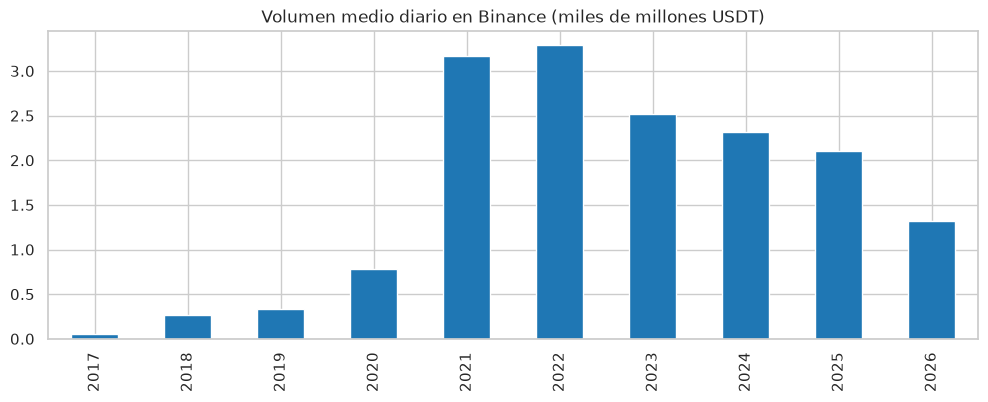

In [10]:
vol_usd = d["quote_volume"].groupby(d.index.year).mean() / 1e9

fig, ax = plt.subplots()
vol_usd.plot.bar(ax=ax, color="tab:blue")
ax.set_title("Volumen medio diario en Binance (miles de millones USDT)")
ax.set_xlabel("")
plt.show()

El **ratio de compra agresiva** es `taker_buy_volume / volume`: la fracción del
volumen ejecutada por compradores que pagan a mercado. > 0,5 indica que dominan
las compras agresivas; < 0,5, las ventas.

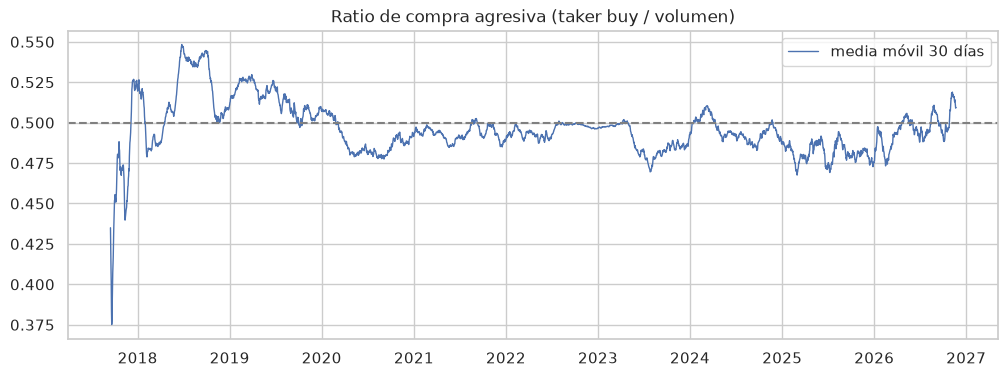

Correlación con el retorno del MISMO día:   0.29
Correlación con el retorno del DÍA SIGUIENTE: 0.022


In [11]:
ratio = ratio_compra_agresiva(d)
var = d["close"].pct_change()

fig, ax = plt.subplots()
ax.plot(ratio.rolling(30).mean(), lw=1, label="media móvil 30 días")
ax.axhline(0.5, color="gray", ls="--")
ax.set_title("Ratio de compra agresiva (taker buy / volumen)")
ax.legend()
plt.show()

print(f"Correlación con el retorno del MISMO día:   {ratio.corr(var):.2f}")
print(f"Correlación con el retorno del DÍA SIGUIENTE: {ratio.corr(var.shift(-1)):.3f}")

**Lectura:**
- El volumen en Binance creció con fuerza hasta 2021-2022 y desde entonces se ha
  reducido.
- El ratio de compra agresiva oscila alrededor de 0,50.
- Se correlaciona con el retorno **del mismo día** (~0,3): describe qué pasó.
  Pero su correlación con el **día siguiente** es prácticamente cero: por sí
  solo, en diario, **no predice**.

**Implicación:** el flujo agresivo no se usará como señal aislada, sino dentro
del contexto Wyckoff (esfuerzo vs. resultado: mucho volumen que no mueve el
precio) y en temporalidades más finas en la Fase 4 (ballenas y CVD).

## 7. Gráfico de velas

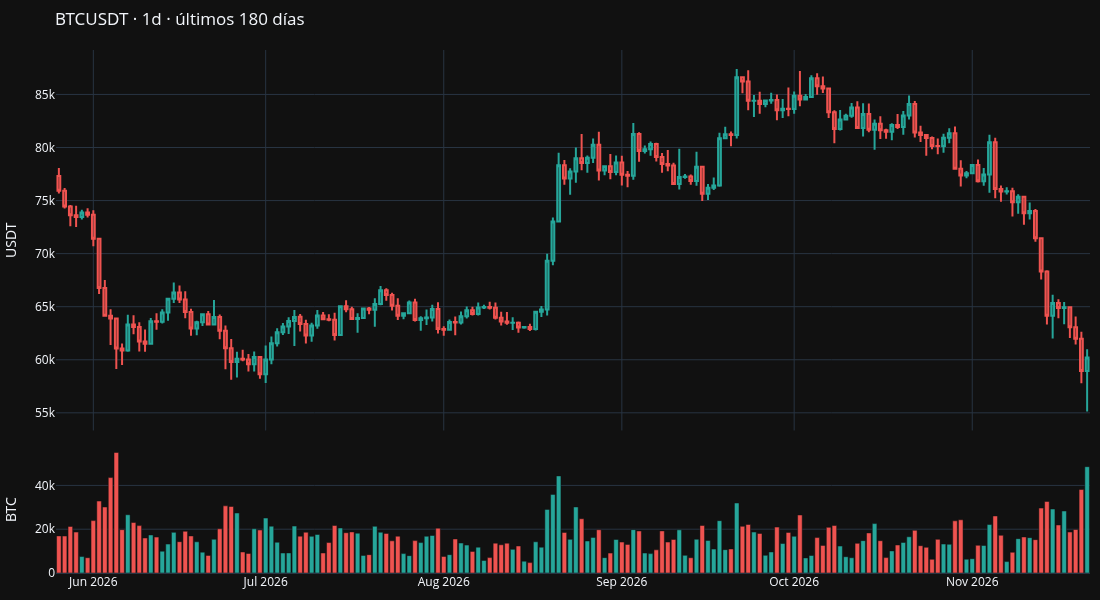

In [12]:
grafico_velas(d.iloc[-180:], "BTCUSDT · 1d · últimos 180 días").show(width=1100)

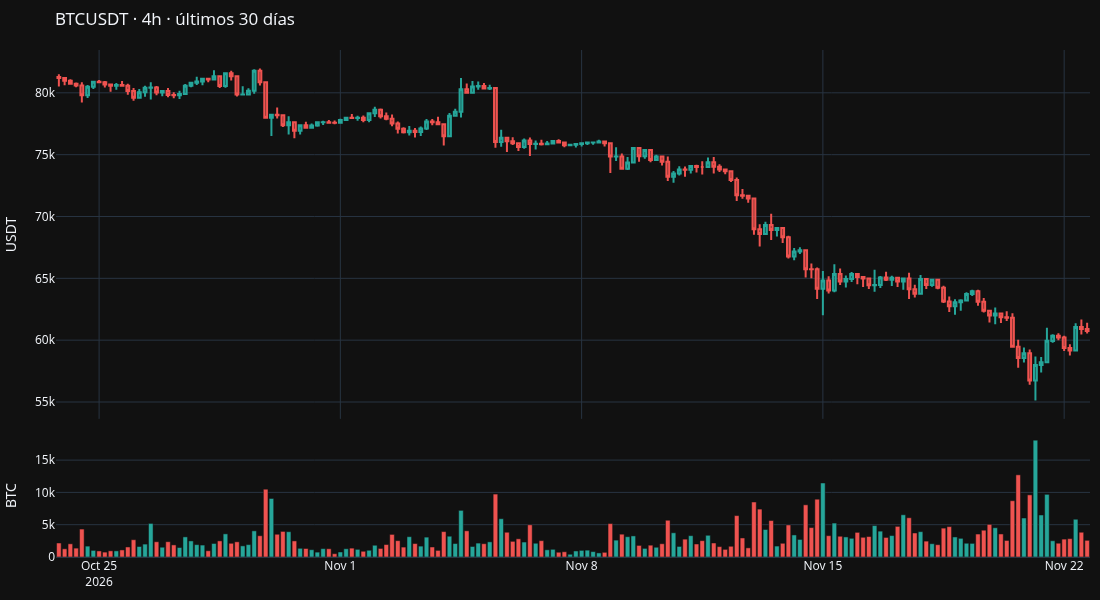

In [13]:
grafico_velas(h.iloc[-180:], "BTCUSDT · 4h · últimos 30 días").show(width=1100)

## 8. Conclusiones

1. **Datos fiables:** sin nulos ni duplicados; 16 velas 4h faltantes (2018-2020),
   documentadas y no imputadas.
2. **Riesgo de colas:** los retornos tienen colas mucho más gruesas que una
   normal y asimetría negativa. El riesgo se medirá con datos reales.
3. **Volatilidad decreciente**, con fases de compresión que son candidatas a
   rangos Wyckoff.
4. **Drawdowns profundos** (hasta −83 %): justifican esperar confirmaciones en
   lugar de comprar caídas.
5. **Flujo agresivo** descriptivo pero no predictivo por sí solo en diario.

**Siguiente paso → Fase 3:** perfil de volumen (POC, VAH, VAL) para localizar
los niveles de precio donde se concentró el volumen.